# NYC Yellow Taxi — Trip Duration Model (January 2025)

## 1. Imports

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

sys.path.append("..")   # so the notebook can find src/
from src.experiment import fit_and_score, train_and_log
from src.features import FEATURES, build_features, build_zone_xy
from src.train import (BASELINE_PARAMS, BEST_PARAMS, DATA_PATH, DATA_URL, MODEL_NAME,
                       load_data, load_january, split_by_time)
from src.tuning import tune_random_forest

## 2. Load data

In [2]:
# Use the copy cached in data/ by src.train.load_january() if it exists, else download
source = DATA_PATH if DATA_PATH.exists() else DATA_URL

cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime",
        "PULocationID", "DOLocationID"]
df = pd.read_parquet(source, columns=cols)
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID
0,2025-01-01 00:18:38,2025-01-01 00:26:59,229,237
1,2025-01-01 00:32:40,2025-01-01 00:35:13,236,237
2,2025-01-01 00:44:04,2025-01-01 00:46:01,141,141
3,2025-01-01 00:14:27,2025-01-01 00:20:01,244,244
4,2025-01-01 00:21:34,2025-01-01 00:25:06,244,116


## 3. Filter & sort

In [3]:
# Keep only January pickups (some rows have wrong dates), then sort by time
df = df[(df["tpep_pickup_datetime"] >= "2025-01-01") & (df["tpep_pickup_datetime"] < "2025-02-01")]
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

## 4. `prepare()`: compute the trip duration and keep 1-60 minute trips

In [4]:
def prepare(df):
    """Trip duration in minutes, keeping only trips of 1-60 minutes."""
    duration = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    return duration[duration.between(1, 60)].to_frame("duration")

## 5. Clean & sample split (train Jan 1-20 / val Jan 21-25)

In [5]:
# Duration of all clean January trips (df is sorted by pickup time)
d = prepare(df)

# Random 500,000 trips, put back in time order
d = d.sample(n=500_000, random_state=42).sort_index()

# Split by date: train Jan 1-20, validation Jan 21-25.
# The test period (Jan 26-31) is only used once, for the final model.
sample = df.loc[d.index]
tr_s, va_s, _ = split_by_time(sample)
y_train, y_val = d.loc[tr_s, "duration"], d.loc[va_s, "duration"]
print(f"Train: {len(y_train):,}  Val: {len(y_val):,}")

Train: 305,905  Val: 93,772


## 6. Build features (same `src.features` code the API uses)

In [6]:
# Zone centers (data/taxi_zones/ is downloaded on first use) and the model features
zone_xy = build_zone_xy(Path("../data"))
X_sample = build_features(sample, zone_xy)
X_train, X_val = X_sample[tr_s], X_sample[va_s]

## 7. Feature list

In [ ]:
print(FEATURES)

   ## 8. Naive baselines

   Two simple benchmarks without machine learning: the overall median duration, and the median
   duration per pickup/drop-off zone pair.

In [15]:
full = load_january()
tr, va, te = split_by_time(full)

def zone_pair_median(train_df, eval_df):
    """Median duration per (pickup, drop-off) zone pair from train_df; unseen pairs get the overall median."""
    medians = train_df.groupby(["PULocationID", "DOLocationID"])["duration"].median()
    keys = pd.MultiIndex.from_frame(eval_df[["PULocationID", "DOLocationID"]])
    return medians.reindex(keys).fillna(train_df["duration"].median()).values

# Same setup as the models: validation from Jan 1-20, test from Jan 1-25
val_rmse = root_mean_squared_error(full.loc[va, "duration"], zone_pair_median(full[tr], full[va]))
test_rmse = root_mean_squared_error(full.loc[te, "duration"], zone_pair_median(full[tr | va], full[te]))
overall = root_mean_squared_error(full.loc[te, "duration"],
                                  [full.loc[tr | va, "duration"].median()] * te.sum())

print(f"Always the overall median     test RMSE: {overall:.3f}")
print(f"Median per zone pair          val RMSE:  {val_rmse:.3f}   test RMSE: {test_rmse:.3f}")

Always the overall median     test RMSE: 10.090
Median per zone pair          val RMSE:  5.444   test RMSE: 5.327


## 9. Random Forest baseline

In [ ]:
baseline, _ = train_and_log(
    BASELINE_PARAMS,
    X_train[FEATURES], y_train, X_val[FEATURES], y_val,
    run_name="rf-baseline", register_name=MODEL_NAME)

## 10. Optuna tuning

In [ ]:
study = tune_random_forest(X_train[FEATURES], y_train, X_val[FEATURES], y_val)

## 11. Final model: train on Jan 1-25 and test once

The final model is trained on all Jan 1-25 trips (train + validation) with the Optuna settings,
scored once on the test set (Jan 26-31), and logged and registered in MLflow.
The validation check on Jan 1-20 (val RMSE 4.344) comes from an earlier run; see the results summary.

In [ ]:
# All January trips of 1-60 minutes
full = df.join(prepare(df), how="inner")

X_full = build_features(full, zone_xy)
y_full = full["duration"]
tr, va, te = split_by_time(full)
print(f"Train: {tr.sum():,}  Val: {va.sum():,}  Test: {te.sum():,}")

final_25, final_metrics = train_and_log(
    study.best_params, X_full[tr | va], y_full[tr | va], X_full[te], y_full[te],
    run_name="rf-final-jan1-25", eval_name="test", register_name=MODEL_NAME)

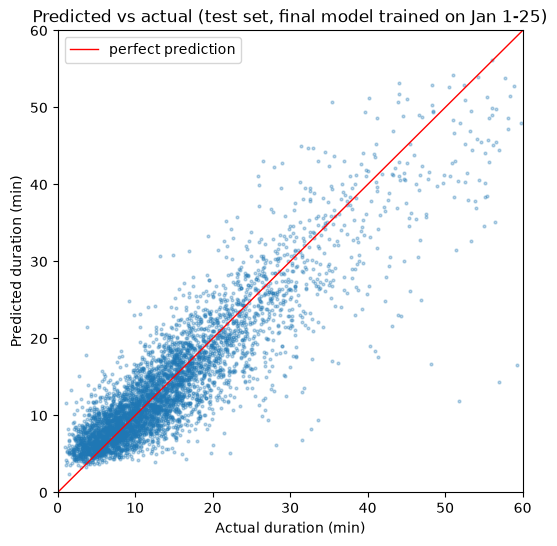

In [11]:
test_pred = final_25.predict(X_full[te])
s = pd.DataFrame({"actual": y_full[te].values, "predicted": test_pred}).sample(5000, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(s["actual"], s["predicted"], s=4, alpha=0.3)
plt.plot([0, 60], [0, 60], color="red", linewidth=1, label="perfect prediction")
plt.xlabel("Actual duration (min)")
plt.ylabel("Predicted duration (min)")
plt.title("Predicted vs actual (test set, final model trained on Jan 1-25)")
plt.xlim(0, 60)
plt.ylim(0, 60)
plt.legend()
plt.show()

In [ ]:
full = load_january()
X_full, y_full = build_features(full, zone_xy), full["duration"]
tr, va, te = split_by_time(full)

def scores(pred_val, pred_test):
    return (root_mean_squared_error(y_full[va], pred_val),
            root_mean_squared_error(y_full[te], pred_test))

def pair_median(train_mask, eval_mask):
    med = full[train_mask].groupby(["PULocationID", "DOLocationID"])["duration"].median()
    keys = pd.MultiIndex.from_frame(full.loc[eval_mask, ["PULocationID", "DOLocationID"]])
    return med.reindex(keys).fillna(y_full[train_mask].median()).values

results = {
    "Always predict the overall median": scores([y_full[tr].median()] * va.sum(),
                                                [y_full[tr | va].median()] * te.sum()),
    "Median per zone pair": scores(pair_median(tr, va), pair_median(tr | va, te)),
}

# Random Forests trained on the 500k sample's Jan 1-20 trips, scored on all val and test trips
sample = load_data()
s_tr = split_by_time(sample)[0]
X_s, y_s = build_features(sample, zone_xy), sample["duration"]
for name, params in [("Random Forest baseline (500k sample)", BASELINE_PARAMS),
                     ("Optuna-tuned (500k sample)", BEST_PARAMS)]:
    m = RandomForestRegressor(**params, n_jobs=-1, random_state=42).fit(X_s[s_tr], y_s[s_tr])
    results[name] = scores(m.predict(X_full[va]), m.predict(X_full[te]))
    del m

pd.DataFrame(results, index=["val_rmse", "test_rmse"]).T.round(4)

,val_rmse,test_rmse
Always predict the overall median,9.9949,10.0902
Median per zone pair,5.4437,5.3265
Random Forest baseline (500k sample),4.5090,4.5093
Optuna-tuned (500k sample),4.4662,4.4619


## 12. Results summary

Time-based split on 1-60 minute trips: **train Jan 1-20 · validation Jan 21-25 · test Jan 26-31**.
Settings and features were chosen on validation only. All models are scored on all validation
trips (637,543) and all test trips (680,825).

| Model | Validation RMSE | Test RMSE |
|---|---|---|
| Always predict the overall median | 9.995 | 10.090 |
| Median per pickup/drop-off zone pair | 5.444 | 5.327 |
| Random Forest baseline (50 trees, 500k sample) | 4.509 | 4.509 |
| Optuna-tuned (20 trials, 500k sample) | 4.466 | 4.462 |
| **Final** (tuned, all 2.7M Jan 1-25 trips) | – | **4.312** |

"–": the final model is trained on the validation days, so it has no validation score.
The same settings trained on Jan 1-20 scored 4.344 on validation.

**Key points**
- The final model is 19% better than the zone-pair median and 57% better than a single guess.
- More data helped more than tuning: tuning gained ~0.04 min, training on all trips ~0.15 min.
- Tuned settings: 200 trees, max_depth 25, min_samples_leaf 8, max_features 0.5 (tuned on the 500k sample).
- Results cover 1-60 minute trips only; broken raw records must be filtered before prediction.

**Serving:** both models are registered in MLflow as `nyc-taxi-duration-rf`; the `champion` alias is
set by hand. The final model is several GB and needs more Docker memory than the default.